# Figure



Saved /home/felicien/code/tweets_ems_calls/Figures/outputs/fig_auroc_lexicon.pdf and .png
Saved /home/felicien/code/tweets_ems_calls/Figures/outputs/fig_auroc_bert.pdf and .png
Saved /home/felicien/code/tweets_ems_calls/Figures/outputs/fig_auroc_both.pdf and .png


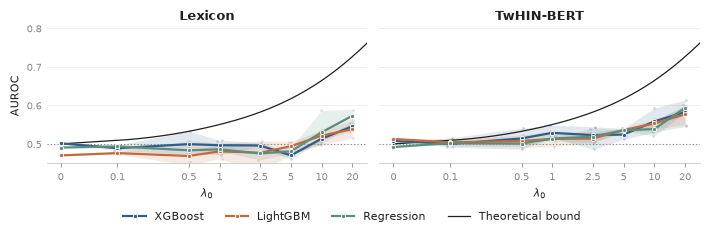

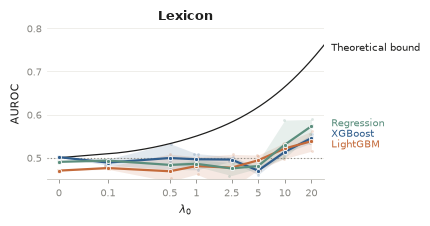

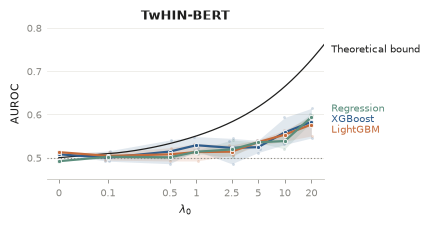

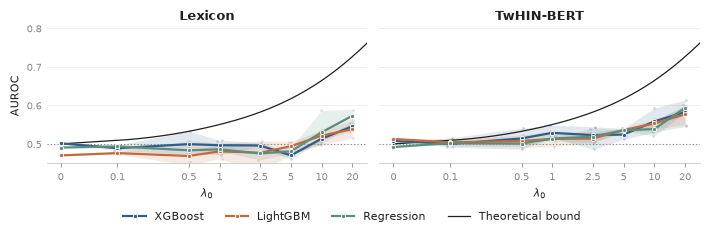

In [1]:
from auroc_vs_lambda import load_experiment, plot_models_vs_lambda, plot_side_by_side
from pathlib import Path

def find_repo_root(start: Path) -> Path:
    """Walk upwards until the semi-synthetic experiment directory is visible."""
    for candidate in [start, *start.parents]:
        if (candidate / "Experiments" / "semi_synthetic" / "outputs").is_dir():
            return candidate
    raise FileNotFoundError(f"No Experiments/semi_synthetic/outputs below {start}")


REPO_ROOT = find_repo_root(Path.cwd().resolve())

OUTPUTS = REPO_ROOT / "Experiments" / "semi_synthetic" / "outputs"

OUTPUT_DIR = REPO_ROOT / "Figures" / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

lexicon = load_experiment(OUTPUTS, "lexicon")
bert = load_experiment(OUTPUTS, "bert")

# one figure per experiment
plot_models_vs_lambda(lexicon, OUTPUT_DIR / "fig_auroc_lexicon", title="Lexicon")
plot_models_vs_lambda(bert, OUTPUT_DIR / "fig_auroc_bert", title="TwHIN-BERT")
plot_side_by_side({"Lexicon": lexicon, "TwHIN-BERT": bert}, OUTPUT_DIR / "fig_auroc_both")

In [3]:
from auroc_vs_lambda import load_experiment, auroc_table

lexicon = load_experiment(OUTPUTS, "lexicon", max_lambda=20)
bert = load_experiment(OUTPUTS, "bert", max_lambda=20)

table = auroc_table({"Lexicon": lexicon, "TwHIN-BERT": bert})


=== Lexicon: mean test AUROC (folds, then seeds) [seed min-max] ===
model                XGBoost             LightGBM           Regression  Bound
lambda0                                                                      
0.0      0.501 [0.501-0.501]  0.470 [0.470-0.470]  0.491 [0.491-0.491]  0.500
0.1      0.489 [0.483-0.497]  0.476 [0.473-0.480]  0.493 [0.491-0.495]  0.509
0.5      0.499 [0.473-0.533]  0.469 [0.445-0.508]  0.483 [0.483-0.485]  0.533
1.0      0.497 [0.472-0.510]  0.481 [0.462-0.502]  0.486 [0.480-0.496]  0.550
2.5      0.496 [0.492-0.503]  0.477 [0.429-0.508]  0.475 [0.459-0.489]  0.583
5.0      0.470 [0.461-0.479]  0.494 [0.472-0.506]  0.481 [0.476-0.491]  0.617
10.0     0.514 [0.511-0.517]  0.522 [0.498-0.535]  0.530 [0.499-0.587]  0.664
20.0     0.546 [0.534-0.554]  0.538 [0.515-0.561]  0.573 [0.554-0.589]  0.726

=== TwHIN-BERT: mean test AUROC (folds, then seeds) [seed min-max] ===
model                XGBoost             LightGBM           Regression  Bound
l